# Иные деревья поиска

> Учебный конспект. Исходные примеры и порядок изложения сохранены.

**Навигация:** [обзор темы](../README.md) · [общий каталог теории](../../docs/theory/README.md)

---


# Иные деревья поиска



## Красно-чёрное дерево

**Идея.** Узлы красим в красный и чёрный; после вставки/удаления чиним дерево перекраской и поворотами. Высота остаётся $O(\log n)$.

**Пять правил:**
- ✅ Каждый узел — либо красный, либо чёрный
- ✅ Корень — всегда чёрный
- ✅ Все пустые места (NIL) считаются чёрными
- ✅ У красного узла оба ребёнка — чёрные
- ✅ На всех путях от любого узла до пустых мест — одинаковое число чёрных узлов
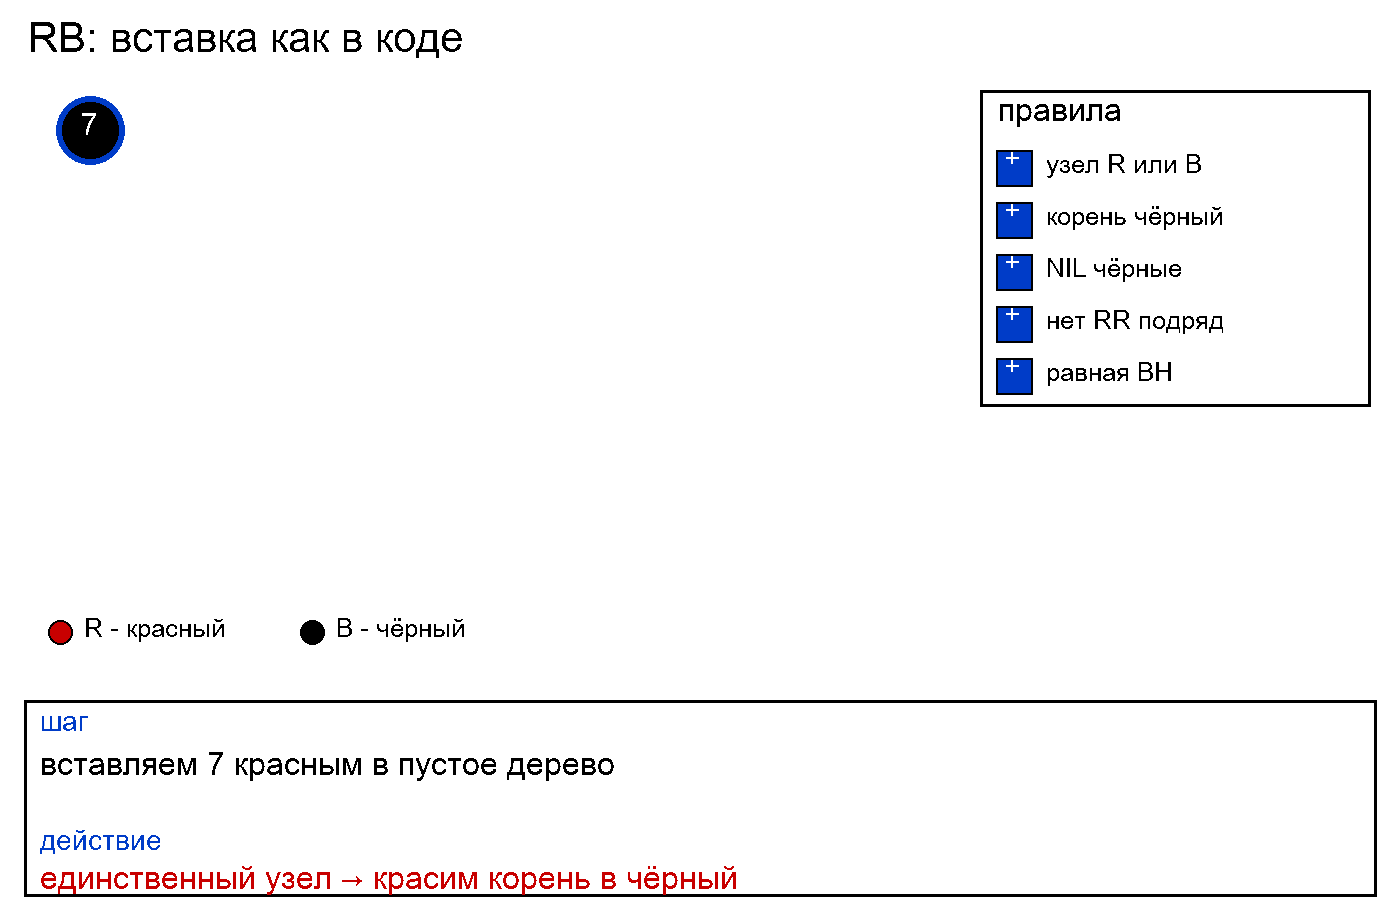


In [4]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional


@dataclass
class RBNode:
    key: int
    color: str  # "R" | "B"
    left: Optional["RBNode"] = None
    right: Optional["RBNode"] = None
    parent: Optional["RBNode"] = None


def _check_no_rr(node: RBNode | None) -> bool:
    if node is None:
        return True
    if node.color == "R":
        for ch in (node.left, node.right):
            if ch is not None and ch.color == "R":
                return False
    return _check_no_rr(node.left) and _check_no_rr(node.right)


def _black_height(node: RBNode | None) -> int | None:
    if node is None:
        return 0
    lh = _black_height(node.left)
    rh = _black_height(node.right)
    if lh is None or rh is None or lh != rh:
        return None
    return lh + (1 if node.color == "B" else 0)


def rb_verdict(root: RBNode | None) -> None:
    """Одна итоговая проверка правил: ✅ или ❌ с описанием."""
    if root is None:
        print("✅ пустое дерево — правила выполнены")
        return
    if root.color != "B":
        print("❌ корень должен быть чёрным")
        return
    if not _check_no_rr(root):
        print("❌ есть два красных подряд (родитель–ребёнок)")
        return
    if _black_height(root) is None:
        print("❌ чёрная высота на путях к листьям разная")
        return
    print("✅ правила выполнены: корень чёрный, нет RR, чёрная высота равна")


def rotate_left(root: RBNode, x: RBNode) -> RBNode:
    y = x.right
    assert y is not None
    x.right = y.left
    if y.left:
        y.left.parent = x
    y.parent = x.parent
    if x.parent is None:
        root = y
    elif x is x.parent.left:
        x.parent.left = y
    else:
        x.parent.right = y
    y.left = x
    x.parent = y
    return root


def rotate_right(root: RBNode, y: RBNode) -> RBNode:
    x = y.left
    assert x is not None
    y.left = x.right
    if x.right:
        x.right.parent = y
    x.parent = y.parent
    if y.parent is None:
        root = x
    elif y is y.parent.left:
        y.parent.left = x
    else:
        y.parent.right = x
    x.right = y
    y.parent = x
    return root


def rb_insert(root: RBNode | None, key: int) -> RBNode:
    node = RBNode(key, "R")
    if root is None:
        node.color = "B"
        print(f"действие: вставляем {key} красным → единственный узел, красим корень в чёрный")
        return node

    cur, parent = root, None
    while cur:
        parent = cur
        if key == cur.key:
            print(f"действие: ключ {key} уже есть — пропускаем")
            return root
        cur = cur.left if key < cur.key else cur.right
    node.parent = parent
    if key < parent.key:
        parent.left = node
    else:
        parent.right = node
    print(f"действие: вставляем {key} красным в лист")

    while node.parent and node.parent.color == "R":
        gp = node.parent.parent
        if gp is None:
            break
        if node.parent is gp.left:
            uncle = gp.right
            if uncle and uncle.color == "R":
                print("действие: дядя красный → перекраска (родитель и дядя в чёрный, дед в красный)")
                node.parent.color = "B"
                uncle.color = "B"
                gp.color = "R"
                node = gp
            else:
                if node is node.parent.right:
                    print("действие: зигзаг → поворот влево у родителя (делаем линию)")
                    node = node.parent
                    root = rotate_left(root, node)
                print("действие: линия → поворот вправо у дедушки + перекраска")
                node.parent.color = "B"
                gp.color = "R"
                root = rotate_right(root, gp)
        else:
            uncle = gp.left
            if uncle and uncle.color == "R":
                print("действие: дядя красный → перекраска (родитель и дядя в чёрный, дед в красный)")
                node.parent.color = "B"
                uncle.color = "B"
                gp.color = "R"
                node = gp
            else:
                if node is node.parent.left:
                    print("действие: зигзаг → поворот вправо у родителя (делаем линию)")
                    node = node.parent
                    root = rotate_right(root, node)
                print("действие: линия → поворот влево у дедушки + перекраска")
                node.parent.color = "B"
                gp.color = "R"
                root = rotate_left(root, gp)

    while root.parent:
        root = root.parent
    if root.color == "R":
        print("действие: корень красный → красим в чёрный")
        root.color = "B"
    return root


def _min_node(node: RBNode) -> RBNode:
    while node.left:
        node = node.left
    return node


def rb_delete(root: RBNode | None, key: int) -> RBNode | None:
    if root is None:
        return None

    def find(n: RBNode | None, k: int) -> RBNode | None:
        while n:
            if k == n.key:
                return n
            n = n.left if k < n.key else n.right
        return None

    target = find(root, key)
    if target is None:
        print(f"действие: удаление {key} — ключа нет, дерево не меняем")
        return root

    if target.left and target.right:
        succ = _min_node(target.right)
        print(f"действие: у {key} два ребёнка → копируем ключ преемника {succ.key}, удаляем преемника")
        target.key = succ.key
        target = succ
    else:
        print(f"действие: удаляем узел {key} (лист или один ребёнок)")

    child = target.left or target.right
    parent = target.parent
    was_black = target.color == "B"

    if child:
        child.parent = parent
    if parent is None:
        root = child
    elif target is parent.left:
        parent.left = child
    else:
        parent.right = child

    if root is None:
        print("действие: дерево стало пустым")
        return None

    if not was_black:
        print("действие: удалили красный — двойного чёрного нет")
        return root

    print("действие: удалили чёрный — восстанавливаем (учебно: корень красим в чёрный; полный fixup — на слайдах)")
    while root.parent:
        root = root.parent
    root.color = "B"
    return root


INSERTS = [7, 3, 18, 10, 22, 8, 11, 26]
DELETES = [11, 8, 22, 3, 26, 18, 10]

rb_root: RBNode | None = None
for k in INSERTS:
    rb_root = rb_insert(rb_root, k)
for k in DELETES:
    rb_root = rb_delete(rb_root, k)

print("--- итог ---")
rb_verdict(rb_root)


действие: вставляем 7 красным → единственный узел, красим корень в чёрный
действие: вставляем 3 красным в лист
действие: вставляем 18 красным в лист
действие: вставляем 10 красным в лист
действие: дядя красный → перекраска (родитель и дядя в чёрный, дед в красный)
действие: корень красный → красим в чёрный
действие: вставляем 22 красным в лист
действие: вставляем 8 красным в лист
действие: дядя красный → перекраска (родитель и дядя в чёрный, дед в красный)
действие: вставляем 11 красным в лист
действие: вставляем 26 красным в лист
действие: удаляем узел 11 (лист или один ребёнок)
действие: удалили красный — двойного чёрного нет
действие: удаляем узел 8 (лист или один ребёнок)
действие: удалили красный — двойного чёрного нет
действие: удаляем узел 22 (лист или один ребёнок)
действие: удалили чёрный — восстанавливаем (учебно: корень красим в чёрный; полный fixup — на слайдах)
действие: удаляем узел 3 (лист или один ребёнок)
действие: удалили чёрный — восстанавливаем (учебно: корень краси

### Оценка сложности (RB)

| Операция | Время | Память |
| --- | --- | --- |
| поиск | $O(\log n)$    | $O(n)$ |
|  вставка | $O(\log n)$     | $O(n)$ |
| удаление | $O(\log n)$    | $O(n)$ |

**Когда выбирать.** Если нужна гарантия $O(\log n)$ в map/set (часто внутри `std::map`, TreeMap).

**Когда не стоит.** Редкие перестроения


## B-Tree

**Идея.** В узле несколько ключей и много детей → дерево ниже → меньше чтений с диска.

**Важно.** Параметр $t$: в узле от $t-1$ до $2t-1$ ключей (корень может быть меньше). При переполнении — split.



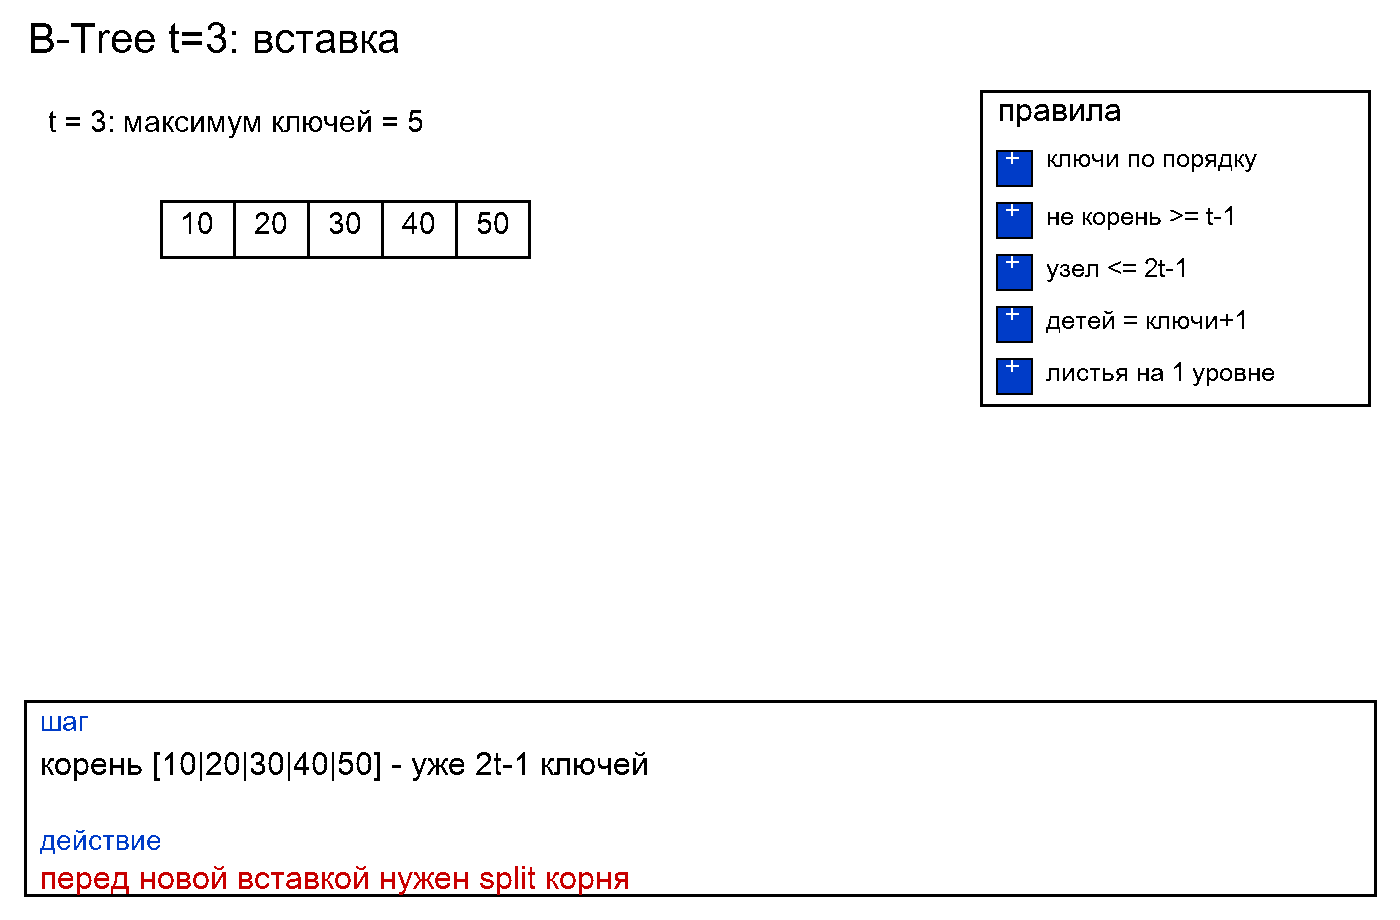

In [5]:
from __future__ import annotations


class BTreeNode:
    def __init__(self, t: int, leaf: bool = True) -> None:
        self.t = t
        self.leaf = leaf
        self.keys: list[int] = []
        self.children: list[BTreeNode] = []


class BTree:
    def __init__(self, t: int = 3) -> None:
        self.t = t
        self.root = BTreeNode(t, leaf=True)

    def _ok_node(self, node: BTreeNode, is_root: bool) -> str | None:
        lo, hi = self.t - 1, 2 * self.t - 1
        n = len(node.keys)
        if not is_root and n < lo:
            return f"в узле {n} ключей, нужно ≥ {lo}"
        if n > hi:
            return f"в узле {n} ключей, нужно ≤ {hi}"
        if not node.leaf and len(node.children) != n + 1:
            return "число детей ≠ число ключей + 1"
        for ch in node.children:
            err = self._ok_node(ch, is_root=False)
            if err:
                return err
        return None

    def verdict(self) -> None:
        err = self._ok_node(self.root, is_root=True)
        if err:
            print(f"❌ пределы t нарушены: {err}")
        else:
            print(f"✅ пределы t соблюдены (t={self.t}: в некорневом узле {self.t - 1}…{2 * self.t - 1} ключей)")

    def search(self, key: int) -> bool:
        node = self.root
        while True:
            i = 0
            while i < len(node.keys) and key > node.keys[i]:
                i += 1
            if i < len(node.keys) and key == node.keys[i]:
                return True
            if node.leaf:
                return False
            node = node.children[i]

    def split_child(self, parent: BTreeNode, i: int) -> None:
        t = self.t
        y = parent.children[i]
        z = BTreeNode(t, leaf=y.leaf)
        mid = y.keys[t - 1]
        z.keys = y.keys[t:]
        y.keys = y.keys[: t - 1]
        if not y.leaf:
            z.children = y.children[t:]
            y.children = y.children[:t]
        parent.children.insert(i + 1, z)
        parent.keys.insert(i, mid)

    def insert(self, key: int) -> None:
        root = self.root
        if len(root.keys) == 2 * self.t - 1:
            print(f"действие: корень переполнен перед вставкой {key} → поднимаем середину, split")
            new_root = BTreeNode(self.t, leaf=False)
            new_root.children = [root]
            self.root = new_root
            self.split_child(new_root, 0)
        self._insert_nonfull(self.root, key)
        print(f"действие: вставляем {key}")

    def _insert_nonfull(self, node: BTreeNode, key: int) -> None:
        i = len(node.keys) - 1
        if node.leaf:
            node.keys.append(0)
            while i >= 0 and key < node.keys[i]:
                node.keys[i + 1] = node.keys[i]
                i -= 1
            node.keys[i + 1] = key
            return
        while i >= 0 and key < node.keys[i]:
            i -= 1
        i += 1
        if len(node.children[i].keys) == 2 * self.t - 1:
            print(f"действие: ребёнок переполнен на пути к {key} → split, затем спуск")
            self.split_child(node, i)
            if key > node.keys[i]:
                i += 1
        self._insert_nonfull(node.children[i], key)

    def delete(self, key: int) -> None:
        print(f"действие: удаляем {key}")
        self._delete(self.root, key)
        if not self.root.keys and self.root.children:
            print("действие: корень опустел → высота уменьшилась")
            self.root = self.root.children[0]

    def _delete(self, node: BTreeNode, key: int) -> None:
        idx = 0
        while idx < len(node.keys) and node.keys[idx] < key:
            idx += 1
        if idx < len(node.keys) and node.keys[idx] == key:
            if node.leaf:
                node.keys.pop(idx)
                print("действие: ключ в листе → простое удаление")
                return
            pred = node.children[idx]
            while not pred.leaf:
                pred = pred.children[-1]
            pred_key = pred.keys[-1]
            print(f"действие: ключ во внутреннем узле → заменяем на предшественника {pred_key}")
            node.keys[idx] = pred_key
            self._delete(node.children[idx], pred_key)
            return
        if node.leaf:
            print("действие: ключа нет")
            return
        child = node.children[idx]
        if len(child.keys) == self.t - 1:
            self._fill(node, idx)
            if idx > len(node.keys):
                idx -= 1
        self._delete(node.children[idx], key)

    def _fill(self, node: BTreeNode, idx: int) -> None:
        t = self.t
        if idx > 0 and len(node.children[idx - 1].keys) >= t:
            print("действие: у ребёнка мало ключей → занимаем у левого соседа")
            child = node.children[idx]
            left = node.children[idx - 1]
            child.keys.insert(0, node.keys[idx - 1])
            if not child.leaf:
                child.children.insert(0, left.children.pop())
            node.keys[idx - 1] = left.keys.pop()
        elif idx < len(node.children) - 1 and len(node.children[idx + 1].keys) >= t:
            print("действие: у ребёнка мало ключей → занимаем у правого соседа")
            child = node.children[idx]
            right = node.children[idx + 1]
            child.keys.append(node.keys[idx])
            if not child.leaf:
                child.children.append(right.children.pop(0))
            node.keys[idx] = right.keys.pop(0)
        else:
            print("действие: у ребёнка мало ключей и занять не у кого → сливаем с соседом")
            if idx < len(node.children) - 1:
                self._merge(node, idx)
            else:
                self._merge(node, idx - 1)

    def _merge(self, node: BTreeNode, idx: int) -> None:
        child = node.children[idx]
        sibling = node.children[idx + 1]
        child.keys.append(node.keys.pop(idx))
        child.keys.extend(sibling.keys)
        if not child.leaf:
            child.children.extend(sibling.children)
        node.children.pop(idx + 1)


DATA = [10, 20, 5, 6, 12, 30, 7, 17, 3, 4, 8, 11, 13, 15, 16, 18, 19, 25, 28, 35]
bt = BTree(t=3)
for x in DATA:
    bt.insert(x)

print(f"действие: поиск 15 → {'найден' if bt.search(15) else 'нет'}")
print(f"действие: поиск 99 → {'найден' if bt.search(99) else 'нет'}")

print("--- итог ---")
bt.verdict()

print("действие: учебные удаления (полный разбор merge/borrow — на слайдах)")
for x in [4, 16]:
    bt.delete(x)


действие: вставляем 10
действие: вставляем 20
действие: вставляем 5
действие: вставляем 6
действие: вставляем 12
действие: корень переполнен перед вставкой 30 → поднимаем середину, split
действие: вставляем 30
действие: вставляем 7
действие: вставляем 17
действие: вставляем 3
действие: вставляем 4
действие: ребёнок переполнен на пути к 8 → split, затем спуск
действие: вставляем 8
действие: вставляем 11
действие: ребёнок переполнен на пути к 13 → split, затем спуск
действие: вставляем 13
действие: вставляем 15
действие: вставляем 16
действие: вставляем 18
действие: вставляем 19
действие: вставляем 25
действие: ребёнок переполнен на пути к 28 → split, затем спуск
действие: вставляем 28
действие: вставляем 35
действие: поиск 15 → найден
действие: поиск 99 → нет
--- итог ---
✅ пределы t соблюдены (t=3: в некорневом узле 2…5 ключей)
действие: учебные удаления (полный разбор merge/borrow — на слайдах)
действие: удаляем 4
действие: у ребёнка мало ключей → занимаем у правого соседа
действие: к

### Оценка сложности (B-Tree)

| Операция | Узлов на пути | Память |
| --- | --- | --- |
| поиск / вставка / удаление | $O(\log_t n)$ | $O(n)$ |

**Когда выбирать.** Много данных на диске / в БД; большой фактор ветвления.

**Когда не стоит.** Только RAM и частые обновления одного ключа — RB проще.


## Trie (префиксное дерево)

**Идея.** Дерево, где каждый узел — это префикс, а каждое ребро — один символ. Путь от корня до узла даёт строку
- Корень — пустая строка
- Ребро = один символ
- Узел = префикс
- Флаг конца слова


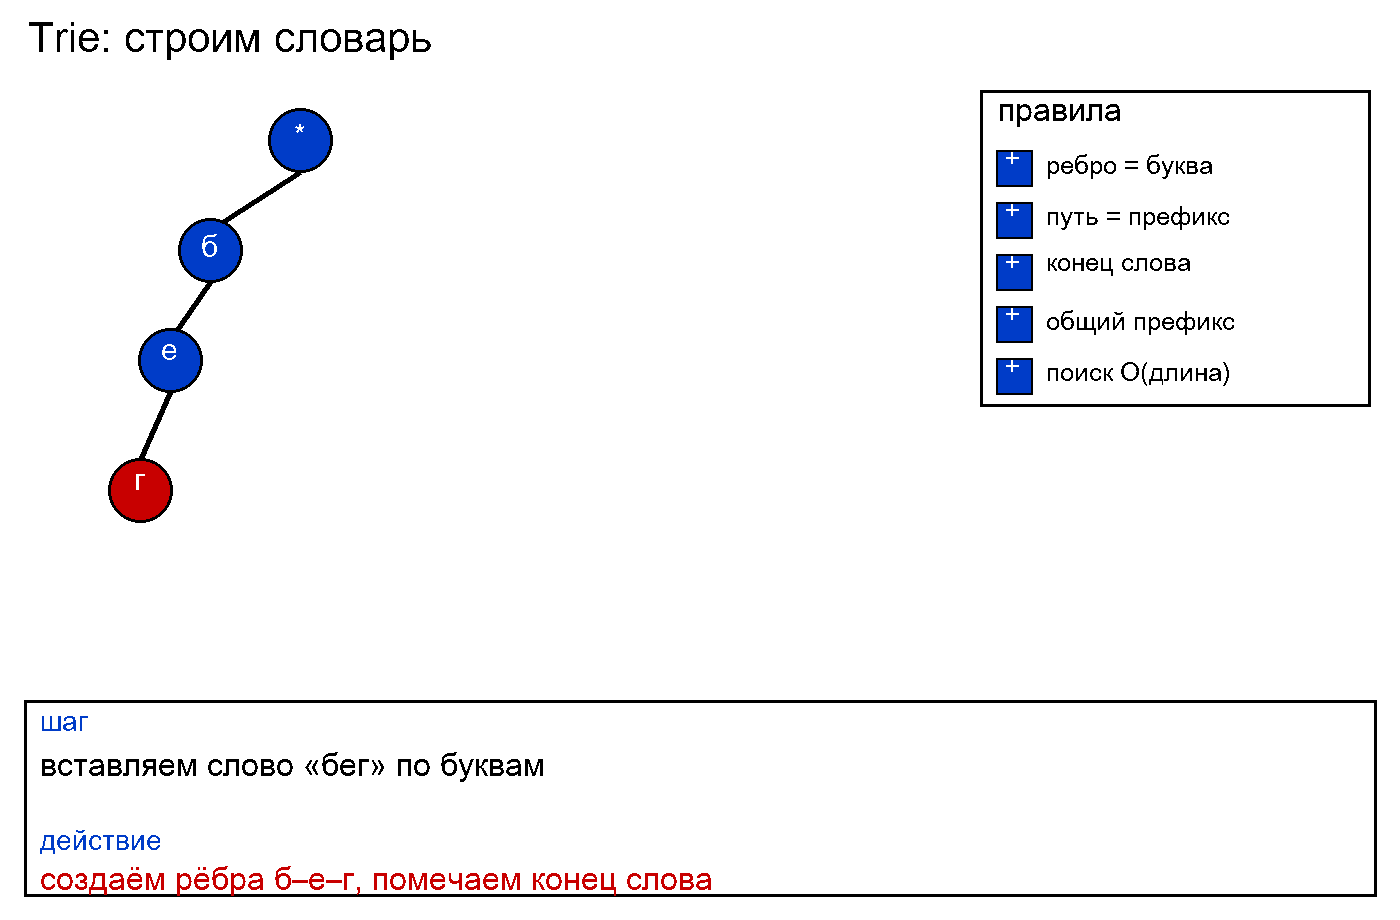

In [6]:
from __future__ import annotations


class TrieNode:
    def __init__(self) -> None:
        self.children: dict[str, TrieNode] = {}
        self.is_word = False


class Trie:
    def __init__(self) -> None:
        self.root = TrieNode()

    def insert(self, word: str) -> None:
        print(f"действие: вставляем «{word}» — идём по буквам, при необходимости создаём рёбра")
        node = self.root
        for ch in word:
            node = node.children.setdefault(ch, TrieNode())
        node.is_word = True

    def words_with_prefix(self, prefix: str) -> list[str]:
        print(f"действие: ищем префикс «{prefix}», затем обходим поддерево")
        node = self.root
        for ch in prefix:
            if ch not in node.children:
                return []
            node = node.children[ch]
        out: list[str] = []

        def dfs(n: TrieNode, path: str) -> None:
            if n.is_word:
                out.append(path)
            for ch, child in n.children.items():
                dfs(child, path + ch)

        dfs(node, prefix)
        return out


WORDS = [
    "бег", "бегать", "беготня", "беговой", "бегство",
    "беглец", "бедовый", "беда", "бедный", "бедро",
]
trie = Trie()
for w in WORDS:
    trie.insert(w)

a = trie.words_with_prefix("бег")
b = trie.words_with_prefix("бед")
print("--- итог ---")
if a and b:
    print(f"✅ префиксы найдены: «бег» → {a}; «бед» → {b}")
else:
    print("❌ ожидали непустые списки по префиксам «бег» и «бед»")


действие: вставляем «бег» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «бегать» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «беготня» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «беговой» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «бегство» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «беглец» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «бедовый» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «беда» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «бедный» — идём по буквам, при необходимости создаём рёбра
действие: вставляем «бедро» — идём по буквам, при необходимости создаём рёбра
действие: ищем префикс «бег», затем обходим поддерево
действие: ищем префикс «бед», затем обходим поддерево
--- итог ---
✅ префиксы найдены: «бег» → ['бег', 'бегать', 'беготня', 'беговой', 'бегство', 'беглец']; «

## Segment Tree

**Идея.** Дерево над массивом. Каждый узел отвечает за отрезок массива. В узле хранится агрегат (сумма, минимум, максимум) для этого отрезка.

- Корень = весь массив
- Дети = половины отрезка
- Листья = отдельные элементы
- В узле — агрегат
- Агрегат родителя = объединение детей


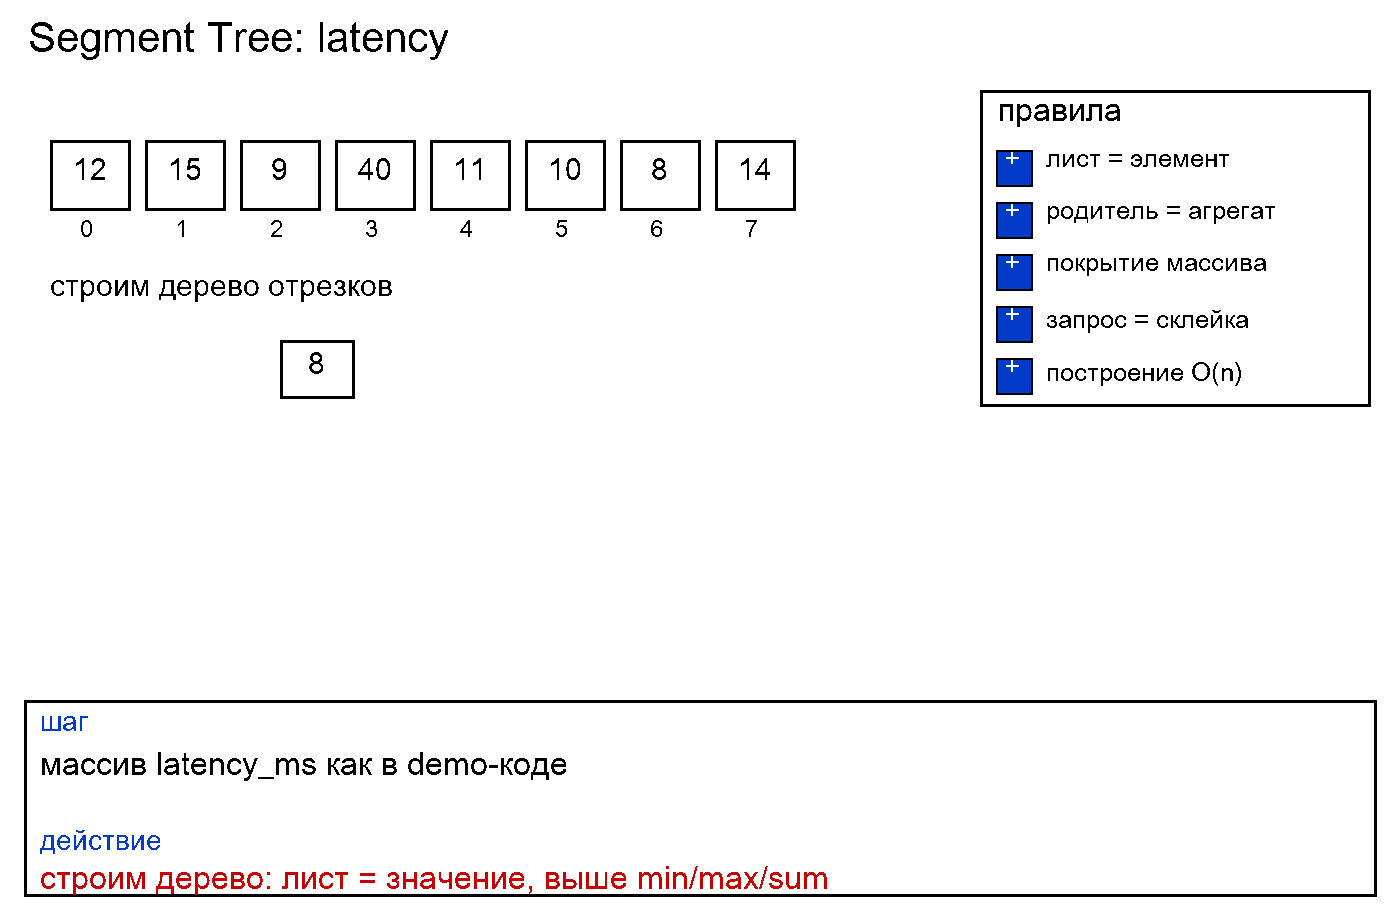

In [7]:
from __future__ import annotations


class SegmentTree:
    def __init__(self, data: list[float]) -> None:
        self.n = len(data)
        self.min_t = [0.0] * (4 * self.n)
        self.max_t = [0.0] * (4 * self.n)
        self.sum_t = [0.0] * (4 * self.n)
        print(f"действие: строим дерево по массиву длины {self.n} — в листьях значения, выше — агрегаты")
        if self.n:
            self._build(1, 0, self.n - 1, data)

    def _build(self, v: int, tl: int, tr: int, data: list[float]) -> None:
        if tl == tr:
            self.min_t[v] = self.max_t[v] = self.sum_t[v] = data[tl]
            return
        tm = (tl + tr) // 2
        self._build(2 * v, tl, tm, data)
        self._build(2 * v + 1, tm + 1, tr, data)
        self.min_t[v] = min(self.min_t[2 * v], self.min_t[2 * v + 1])
        self.max_t[v] = max(self.max_t[2 * v], self.max_t[2 * v + 1])
        self.sum_t[v] = self.sum_t[2 * v] + self.sum_t[2 * v + 1]

    def query(self, left: int, right: int) -> tuple[float, float, float]:
        print(f"действие: запрос [{left}..{right}] — склеиваем O(log n) готовых отрезков")
        mn, mx, sm, cnt = self._query(1, 0, self.n - 1, left, right)
        return mn, mx, sm / cnt

    def _query(self, v: int, tl: int, tr: int, l: int, r: int):
        if l > r:
            return float("inf"), float("-inf"), 0.0, 0
        if l == tl and r == tr:
            return self.min_t[v], self.max_t[v], self.sum_t[v], tr - tl + 1
        tm = (tl + tr) // 2
        a = self._query(2 * v, tl, tm, l, min(r, tm))
        b = self._query(2 * v + 1, tm + 1, tr, max(l, tm + 1), r)
        return min(a[0], b[0]), max(a[1], b[1]), a[2] + b[2], a[3] + b[3]


latency_ms = [12, 15, 9, 40, 11, 10, 8, 14]
st = SegmentTree(latency_ms)
mn, mx, mean = st.query(1, 5)
print("--- итог ---")
expected_min = min(latency_ms[1:6])
if mn == expected_min and mx == max(latency_ms[1:6]):
    print(f"✅ запрос [1..5]: min={mn}, max={mx}, mean={round(mean, 2)}")
else:
    print(f"❌ неверные агрегаты: min={mn}, max={mx}")


действие: строим дерево по массиву длины 8 — в листьях значения, выше — агрегаты
действие: запрос [1..5] — склеиваем O(log n) готовых отрезков
--- итог ---
✅ запрос [1..5]: min=9, max=40, mean=17.0


## Splay Tree

**Идея.** Двоичное дерево поиска, которое само себя настраивает. При каждом обращении к узлу он поднимается в корень через операцию splay. Недавно использованные элементы — ближе к корню.
- Нет хранения баланса
- привызове или вставке - Splay — подъём в корень
- Амортизированная сложность
- Часто используемые элементы — наверху


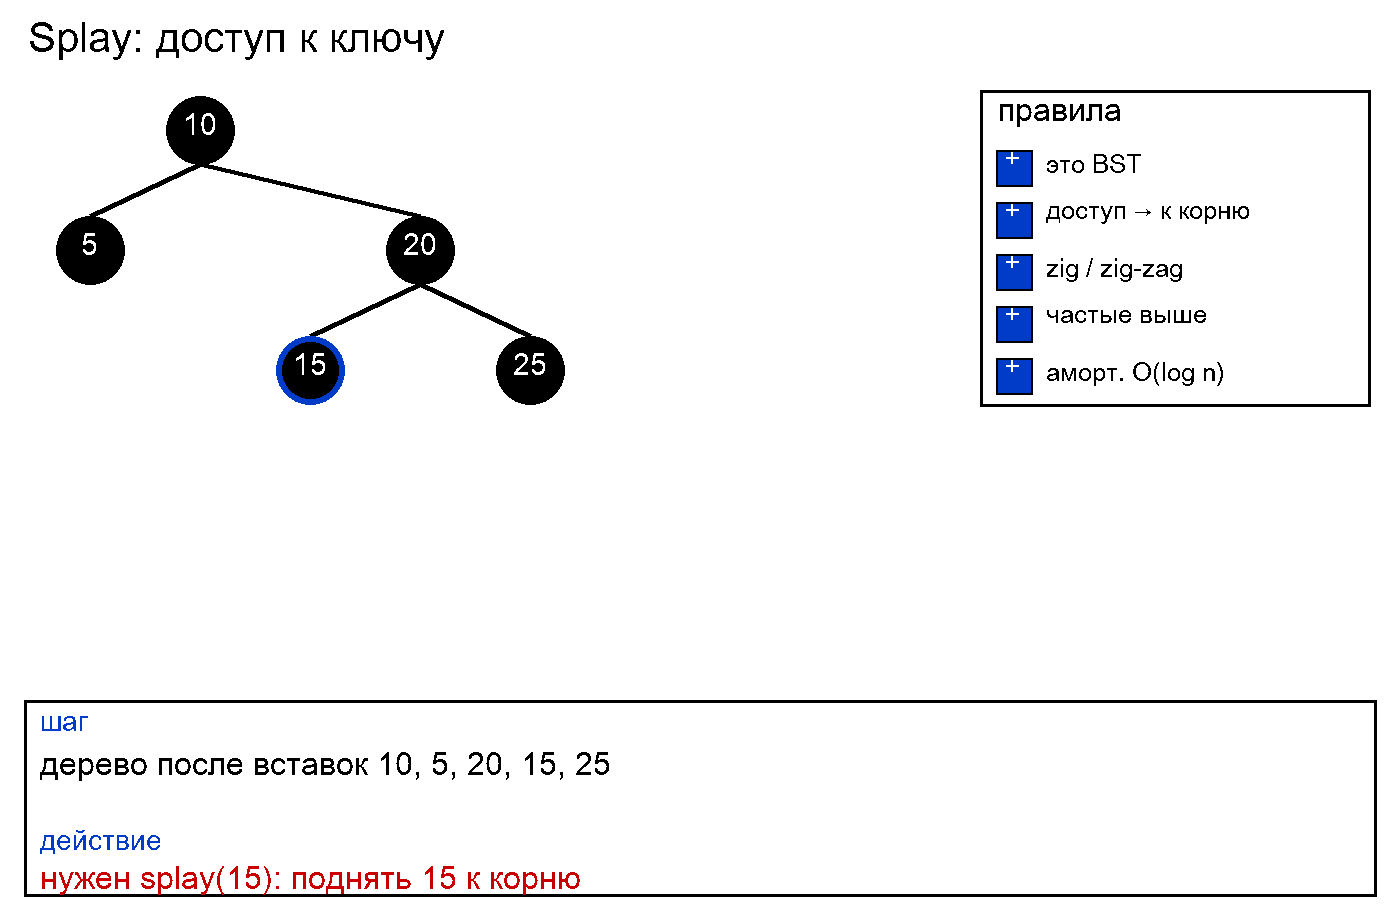

In [8]:
from __future__ import annotations

from dataclasses import dataclass
from typing import Optional


@dataclass
class SplayNode:
    key: int
    left: Optional["SplayNode"] = None
    right: Optional["SplayNode"] = None


def splay_rotate_left(x: SplayNode) -> SplayNode:
    y = x.right
    assert y is not None
    x.right = y.left
    y.left = x
    return y


def splay_rotate_right(x: SplayNode) -> SplayNode:
    y = x.left
    assert y is not None
    x.left = y.right
    y.right = x
    return y


def splay(root: SplayNode | None, key: int) -> SplayNode | None:
    """Поднимает ключ (или последнего посещённого) к корню — учебный top-down splay."""
    if root is None:
        return None
    print(f"действие: splay({key}) — zig / zig-zag, поднимаем узел к корню")
    left_tree = right_tree = None
    left_tail = right_tail = None
    node = root
    while True:
        if key < node.key:
            if node.left is None:
                break
            if key < node.left.key:
                node = splay_rotate_right(node)
                if node.left is None:
                    break
            if right_tree is None:
                right_tree = right_tail = node
            else:
                right_tail.left = node
                right_tail = node
            node = node.left
            right_tail.left = None
        elif key > node.key:
            if node.right is None:
                break
            if key > node.right.key:
                node = splay_rotate_left(node)
                if node.right is None:
                    break
            if left_tree is None:
                left_tree = left_tail = node
            else:
                left_tail.right = node
                left_tail = node
            node = node.right
            left_tail.right = None
        else:
            break
    if left_tail:
        left_tail.right = node.left
    else:
        left_tree = node.left
    if right_tail:
        right_tail.left = node.right
    else:
        right_tree = node.right
    node.left = left_tree
    node.right = right_tree
    return node


def splay_insert(root: SplayNode | None, key: int) -> SplayNode:
    if root is None:
        print(f"действие: вставляем {key} в пустое дерево")
        return SplayNode(key)
    root = splay(root, key)
    assert root is not None
    if root.key == key:
        print(f"действие: ключ {key} уже в корне после splay")
        return root
    print(f"действие: вставляем {key} и делаем его новым корнем")
    node = SplayNode(key)
    if key < root.key:
        node.right = root
        node.left = root.left
        root.left = None
    else:
        node.left = root
        node.right = root.right
        root.right = None
    return node


sp: SplayNode | None = None
for k in [10, 5, 20, 15, 25]:
    sp = splay_insert(sp, k)
sp = splay(sp, 15)
print("--- итог ---")
if sp is not None and sp.key == 15:
    print("✅ после доступа к 15 он в корне (как в кеше)")
else:
    print("❌ ожидали корень 15 после splay")


действие: вставляем 10 в пустое дерево
действие: splay(5) — zig / zig-zag, поднимаем узел к корню
действие: вставляем 5 и делаем его новым корнем
действие: splay(20) — zig / zig-zag, поднимаем узел к корню
действие: вставляем 20 и делаем его новым корнем
действие: splay(15) — zig / zig-zag, поднимаем узел к корню
действие: вставляем 15 и делаем его новым корнем
действие: splay(25) — zig / zig-zag, поднимаем узел к корню
действие: вставляем 25 и делаем его новым корнем
действие: splay(15) — zig / zig-zag, поднимаем узел к корню
--- итог ---
✅ после доступа к 15 он в корне (как в кеше)


## Что выбрать

| Структура | Сильная сторона | Типичный сценарий |
| --- | --- | --- |
| RB | гарантия $O(\log n)$ в RAM | упорядоченный словарь |
| B-Tree | мало уровней на диске | индекс БД / файловая система |
| Trie | общие префиксы | автодополнение |
| Segment Tree | агрегаты на отрезке | min/max/sum по диапазону |
| Splay | частые ключи ближе к корню | локальность доступа |

Пошаговые кейсы RB и B-Tree — в `slides.md`.
